# Coordination de satellites

### Etudiants :
- Jawher JRIBY 3702809
- Mélanie DELLUC 21104033

## 1 - Introduction

L'objectif de ce projet est d'étudier un problème d'allocation multi-agents de tâches dans lequel des tâches d’observations doivent être allouées à des constellations de satellites en orbite autour de la Terre.

...

## 2 - Préparation : Instances et planification des tâches

In [43]:
from typing import Callable
import random
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np

### 2.1 - Générateur aléatoire

Dans un premier temps, nous allons implémenter un générateur aléatoire d'instances du problème EOSCSP à partir d'un nombre de satellites, d'utilisateurs exclusifs et de tâches. Pour cela, nous devons établir les structures de données nécessaires à la représentation du problème (EOSCSP, satellites, utilisateurs, requêtes, observations, solutions) et leurs contraintes associées avant de générer des instances de chaque élément. 

Nous avons commencé par créer des instances aléatoires générales, donc sans se préoccuper de l'exclusivité. Puis, nous y avons ajouté les contraintes supplémentaires liées au problème d'exclusivité (section 2.1.5). 

#### 2.1.1 - Structures de données

In [44]:
class EOSCSP :
    def __init__(self, eoscsp_id : int, S : set['Satellite'], U : set['User'], R : set['Request'], O : set['Observation']):
        self.eoscsp_id = eoscsp_id
        self.S = S
        self.U = U 
        self.R = R
        self.O = O

In [45]:
class Satellite :
    def __init__(self, s_id : int, t_start: float, t_end: float, kappa: int, tau: Callable[['Observation', 'Observation'], float]):
        self.s_id = s_id
        self.t_start = t_start
        self.t_end = t_end
        self.kappa = kappa
        self.tau = tau

In [46]:
class User :
    def __init__(self, u_id : int, e : set[tuple['Satellite', float, float]], p : int):
        self.u_id = u_id
        self.e = e
        self.p = p

In [47]:
class Request :
    def __init__(self, r_id : int, t_start : float, t_end : float, duration : float, reward : float, p : tuple[float, float, float], u : User, thetas : list['Observation']):
        self.r_id = r_id
        self.t_start = t_start
        self.t_end = t_end
        self.duration = duration
        self.reward = reward
        self.p = p
        self.u = u
        self.thetas = thetas

In [48]:
class Observation :
    def __init__(self, o_id : int, t_start : float, t_end : float, duration : float, r : 'Request', reward : float, s : 'Satellite', u : 'User', p : int):
        self.o_id = o_id
        self.t_start = t_start 
        self.t_end = t_end
        self.duration = duration
        self.r = r
        self.reward = reward
        self.s = s
        self.u = u
        self.p = p

In [49]:
class Solution :
    def __init__(self, sol_id : int, M : dict['Observation', float]):
        self.sol_id = sol_id
        self.M = M 

## 2.1.2 - Contraintes générales sur les données

In [50]:
def constraints_EOSCSP():
    return

In [51]:
def constraints_satellites(s):
    errors = []

    if s.t_start >= s.t_end :
        errors.append("Sattelite s : invalid time -> start > end")

    if s.kappa < 1 :
        errors.append("Sattelite s : invalid capacity -> kappa < 1")

    return errors

In [52]:
def constraints_users(u):
    errors = []

    if u.p < 1 :
        errors.append("User u : invalid priority -> p < 1")
    
    return errors

In [53]:
def constraints_requests(r, users):
    errors = []

    if r.t_start >= r.t_end :
        errors.append("Request r : invalid time -> start > end")

    if r.duration <= 0 :
        errors.append("Request r : invalid duration -> duration <= 0")

    if r.reward < 0 :
        errors.append("Request r : invalid reward -> reward < 0")

    #if r.u not in users :
    #    errors.append("Request r: requester does not exist")

    #for o in r.thetas :
    #    if o not in observations :
    #        errors.append("Request r : invalid thetas -> unknown obsevation")
                
    return errors

In [54]:
def constraints_observations(o, requests, satellites):
    errors = []

    if o.t_start >= o.t_end :
        errors.append("Observation o : invalid time -> start > end")

    if o.r not in requests:
        errors.append("Observation o : unknown request")

    if o.s not in satellites:
        errors.append("Observation o : unknown satellite")

    #if o.u.u_id != o.r.u.u_id:
    #    errors.append("Observation o: owner mismatch with request")

    if o.duration != o.r.duration:
        errors.append("Observation o: duration must equal request duration")

    if not (o.s.t_start <= o.t_start < o.t_end <= o.s.t_end):
        errors.append("Observation o: outside satellite horizon")
            
    return errors

In [55]:
def constraints_solutions():
    return

In [56]:
def overlap(a_start, a_end, b_start, b_end, eps=1e-9):
    return (a_start < b_end - eps) and (b_start < a_end - eps)


def constraints_exclusifs_users(u, satellites, users_exclusifs):
    errors = []

    for (s, start, end) in getattr(u, "e", []) or []:
        if s not in satellites:
            errors.append("User u : exclusive references unknown satellite")
        else:
            if not (s.t_start <= start < end <= s.t_end):
                errors.append("User u: exclusive window outside satellite horizon")

    # overlap between exclusives (same satellite)
    for ue in users_exclusifs:
        if ue is u:
            continue
        for (s2, start2, end2) in getattr(ue, "e", []) or []:
            for (s1, start1, end1) in getattr(u, "e", []) or []:
                if s1 == s2 and overlap(start1, end1, start2, end2):
                    errors.append("Overlapping exclusive windows on same satellite")

    return errors


In [57]:
def tau(o,p):
    return 1.0

#### 2.1.3 - Construction d'instances des données (hors exclusivité)

In [58]:
def generate_satellites(nb_satellites, horizon, kappa_min, kappa_max, max_tries=10000):
    S = set()
    
    for i in range(nb_satellites) :
        for j in range(max_tries):
            start = 0
            end = start + horizon
            kappa = random.randint(kappa_min, kappa_max)
            s = Satellite(s_id=i, t_start=start,t_end=end,kappa=kappa,tau=None)
            if constraints_satellites(s) == [] :
                S.add(s)
                break
    return S

In [59]:
def generate_users(nb_users, min_priority=1, max_priority=10, max_tries=10000):
    U = set()

    for i in range(nb_users):
        for j in range(max_tries):
            p = random.randint(min_priority, max_priority)
            u = User(u_id=i, e=set(), p=p,)

            if constraints_users(u) == [] :
                U.add(u)
                break
    return U

In [60]:
def generate_requests(users, nb_requests_per_user, horizon, d_min, d_max, r_min, r_max, max_tries=10000):
    R = set()
    r_id = 0

    for u in users :
        for i in range(nb_requests_per_user) :
            for j in range(max_tries) :
                d = random.uniform(d_min, d_max)
                start = random.uniform(0.0, horizon - d)
                end = start + random.uniform(d, horizon - start)
                reward = random.uniform(r_min, r_max)

                lat = random.uniform(-1.0, 1.0)     # latitude
                lon = random.uniform(-1.0, 1.0)   # longitude
                alt = random.uniform(-1.0, 1.0)    # altitude (km ou m, peu importe ici)
                p = [lat,lon,alt] 
                p=0

                r = Request(r_id=r_id, t_start=start, t_end=end, duration=d, reward=reward, p=p, u=u, thetas=[],)

                if constraints_requests(r, users) == [] :
                    R.add(r)   
                    r_id += 1
                    break
    return R

In [61]:
def generate_observations(satellites, users, requests, opp_per_request, obs_window_min, obs_window_max, max_tries=10000):
    O = set()

    users_by_id = {u.u_id : u for u in users}

    o_id = 0
    for r in requests :
        for i in range(opp_per_request) :
            for j in range(max_tries) :
                s = random.choice(list(satellites))

                d = max(r.duration, random.uniform(obs_window_min, obs_window_max))
                start_min = r.t_start
                start_max = r.t_end - d
                if start_max < start_min :
                    continue

                o_start = random.uniform(start_min, start_max)
                o_end = o_start + d

                o = Observation(o_id=o_id, r=r, u=r.u, s=s, t_start=o_start, t_end=o_end, duration=r.duration, reward=r.reward, p=users_by_id[r.u.u_id].p,)

                if constraints_observations(o, requests, satellites) == [] :
                    O.add(o)
                    r.thetas.append(o_id)
                    o_id += 1
                    break
    
    return O

In [62]:
def generate_EOSCSP(i, satellites, users, requests, observations):
    return EOSCSP(eoscsp_id=i, S=satellites, U=users, R=requests, O=observations)

In [63]:
def generate_users_exclusifs(k, satellites, nb_users, min_priority=1, max_priority=10, e_dur_min=50, e_dur_max=250, max_tries=10000):
    U = set()

    for i in range(nb_users):
        for j in range(max_tries):
            p = random.randint(min_priority, max_priority)

            s = random.choice(list(satellites))
            dur = random.uniform(e_dur_min, e_dur_max)
            horizon = s.t_end - s.t_start
            if dur >= horizon:
                dur = max(1.0, 0.5 * horizon)
            start = random.uniform(s.t_start, s.t_end - dur)
            end = start + dur
            res = set()
            res.add((s,start,end))
            u = User(u_id=i+k, e=res, p=p,) # pour l'instant on suppose qu'il y a qu'une seule fenêtre exclusive par user

            if constraints_users(u) == [] and constraints_exclusifs_users(u, satellites, U) == [] :
                U.add(u)
                break
    return U

#### Fonctions d'affichage

In [64]:
def plot_eoscsp_windows(
    EOSCSP,
    plan=None,
    title="EOSCSP",
    show_labels=True,
    show_exclusives=True,
    show_plan_labels=True,
):

    satellites = EOSCSP.S
    observations = EOSCSP.O
    users = EOSCSP.U

    # --- Satellite order ---
    sat_ids = []
    for idx, s in enumerate(satellites):
        sid = getattr(s, "s_id", idx)
        sat_ids.append(sid)
    sat_ids_sorted = sorted(sat_ids)

    # --- User ids present (from observations + plan + optionally from users) ---
    user_ids = sorted({getattr(o.u, "u_id", 0) for o in observations})
    if plan is not None:
        user_ids = sorted(set(user_ids) | {getattr(obs.u, "u_id", 0) for obs, _, _ in plan})
    if users is not None:
        user_ids = sorted({u.u_id for u in users} | set(user_ids))

    # --- Colors ---
    cmap = plt.get_cmap("tab10")
    user_color = {uid: cmap(i % 10) for i, uid in enumerate(user_ids)}

    fig, ax = plt.subplots(figsize=(12, 7))
    row_height = 0.8
    y_gap = 0.35

    # --- Time bounds: include observations, exclusives and plan ---
    all_starts = [o.t_start for o in observations]
    all_ends = [o.t_end for o in observations]

    if show_exclusives and users is not None:
        for u in users:
            for ew in getattr(u, "e_u", []):
                all_starts.append(ew.t_start)
                all_ends.append(ew.t_end)

    if plan is not None:
        for obs, start, end in plan:
            all_starts.append(start)
            all_ends.append(end)

    t_min = min(all_starts) if all_starts else 0.0
    t_max = max(all_ends) if all_ends else 1.0

    # Helpers
    def y_of_sat_id(sid):
        return sat_ids_sorted.index(sid) * (row_height + y_gap)

    def sid_of_sat(s_obj):
        return getattr(s_obj, "s_id", None)

    # -------------------------
    # 1) Draw exclusive windows (background, hatched)
    # -------------------------
    if show_exclusives and users is not None:
        for u in users:
            uid = getattr(u, "u_id", 0)
            for ew in getattr(u, "e", []):
                sid = sid_of_sat(ew[0])
                if sid is None or sid not in sat_ids_sorted:
                    continue

                y = y_of_sat_id(sid)
                x = ew[1]
                w = ew[2] - ew[1]
                if w <= 0:
                    continue

                hatched = Rectangle(
                    (x, y),
                    w,
                    row_height,
                    facecolor=user_color.get(uid, cmap(0)),
                    edgecolor=user_color.get(uid, cmap(0)),
                    linewidth=1.0,
                    alpha=0.18,
                    hatch="///",
                    zorder=0,
                )
                ax.add_patch(hatched)

    # -------------------------
    # 2) Draw observation windows (transparent)
    # -------------------------
    for o in observations:
        uid = getattr(o.u, "u_id", 0)
        sid = sid_of_sat(o.s)
        if sid is None or sid not in sat_ids_sorted:
            continue

        y = y_of_sat_id(sid)
        x = o.t_start
        w = o.t_end - o.t_start
        if w <= 0:
            continue

        rect = Rectangle(
            (x, y),
            w,
            row_height,
            facecolor=user_color.get(uid, cmap(0)),
            edgecolor="black",
            linewidth=1,
            alpha=0.25,
            zorder=2,
        )
        ax.add_patch(rect)

        if show_labels:
            oid = getattr(o, "o_id", None)
            rid = getattr(getattr(o, "r", None), "r_id", None)
            label = f"o{oid},r{rid}" if oid is not None else "obs"
            ax.text(
                x + w / 2,
                y + row_height / 2,
                label,
                ha="center",
                va="center",
                fontsize=8,
                alpha=0.9,
                zorder=3,
            )

    # -------------------------
    # 3) Draw plan (solid rectangles on top)
    # -------------------------

    #[(<__main__.Observation object at 0x000002C423961580>, 31.02142670863951, 38.86383450771059), 
    #(<__main__.Observation object at 0x000002C423962D80>, 38.86383450771059, 46.706242306781675), 
    #(<__main__.Observation object at 0x000002C4207387D0>, 70.66581629796106, 80.61438527573456)]
    
    if plan is not None:
        for obs, start, end in plan:
            uid = getattr(obs.u, "u_id", 0)
            sid = sid_of_sat(obs.s)
            if sid is None or sid not in sat_ids_sorted:
                continue

            y = y_of_sat_id(sid)

            w = end - start
            if w <= 0:
                continue

            # Solid execution block (slightly shorter height so it looks "inside" the window)
            pad = 0.08
            exec_rect = Rectangle(
                (start, y + pad),
                w,
                row_height - 2 * pad,
                facecolor=user_color.get(uid, cmap(0)),
                edgecolor="black",
                linewidth=2.0,
                alpha=0.85,
                zorder=5,
            )
            ax.add_patch(exec_rect)

            if show_plan_labels:
                oid = getattr(obs, "o_id", None)
                label = f"o{oid}" if oid is not None else "exec"
                ax.text(
                    start + w / 2,
                    y + row_height / 2,
                    label,
                    ha="center",
                    va="center",
                    fontsize=9,
                    alpha=0.95,
                    zorder=6,
                )

    # --- Y axis labels ---
    y_ticks = []
    y_labels = []
    for sid in sat_ids_sorted:
        y_ticks.append(y_of_sat_id(sid) + row_height / 2)
        y_labels.append(f"S{sid}")
    ax.set_yticks(y_ticks)
    ax.set_yticklabels(y_labels)

    # --- X axis ---
    ax.set_xlim(t_min - 0.5, t_max + 0.5)
    ax.set_xlabel("time")
    ax.set_ylabel("satellite")
    ax.set_title(title)

    # --- Legend (users) ---
    handles = []
    labels = []
    for uid in user_ids:
        patch = Rectangle((0, 0), 1, 1, facecolor=user_color[uid], edgecolor="black", alpha=0.25)
        handles.append(patch)
        labels.append(f"u{uid}")
    ax.legend(handles, labels, loc="upper right")

    ax.grid(True, axis="x", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


In [65]:
def format_eoscsp(P, max_items=30) -> str:
    """
    P: instance of EOSCSP
    max_items: limit printed items per section to keep it readable
    """

    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def rid(r): return getattr(r, "r_id", "?")
    def oid(o): return getattr(o, "o_id", "?")

    lines = []
    lines.append(f"EOSCSP instance #{P.eoscsp_id}")
    lines.append(f"|S|={len(P.S)} |U|={len(P.U)} |R|={len(P.R)} |O|={len(P.O)}")
    lines.append("")

    # --- Satellites ---
    lines.append("Satellites:")
    for i, s in enumerate(sorted(P.S, key=lambda x: getattr(x, "s_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.S)-max_items} more)")
            break
        lines.append(
            f"  S{sid(s)}: horizon=[{s.t_start:.2f},{s.t_end:.2f}] kappa={getattr(s,'kappa','?')}"
        )
    lines.append("")

    # --- Users + exclusives ---
    lines.append("Users:")
    for i, u in enumerate(sorted(P.U, key=lambda x: getattr(x, "u_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.U)-max_items} more)")
            break

        e = getattr(u, "e", set())
        lines.append(f"  u{uid(u)}: priority={getattr(u,'p','?')} exclusives={len(e)}")
        # print exclusives
        for j, (s, a, b) in enumerate(sorted(list(e), key=lambda t: (sid(t[0]), t[1]))):
            if j >= 10:
                lines.append("    ...")
                break
            lines.append(f"    - (S{sid(s)}, [{a:.2f},{b:.2f}])")
    lines.append("")

    # --- Requests ---
    lines.append("Requests:")
    for i, r in enumerate(sorted(P.R, key=lambda x: getattr(x, "r_id", 0))):
        if i >= max_items:
            lines.append(f"  ... ({len(P.R)-max_items} more)")
            break
        u = getattr(r, "u", None)
        lines.append(
            f"  r{rid(r)}: user=u{uid(u) if u else '?'} "
            f"duration={getattr(r,'duration','?')} reward={getattr(r,'reward','?')}"
        )
    lines.append("")

    # --- Observations ---
    lines.append("Observations (windows):")
    obs_sorted = sorted(P.O, key=lambda o: (getattr(o.s, "s_id", 0), o.t_start, oid(o)))
    for i, o in enumerate(obs_sorted):
        if i >= max_items:
            lines.append(f"  ... ({len(P.O)-max_items} more)")
            break
        lines.append(
            f"  o{oid(o)}: u{uid(o.u)} on S{sid(o.s)} "
            f"window=[{o.t_start:.2f},{o.t_end:.2f}] "
            f"dur={o.duration:.2f} reward={o.reward:.2f} "
            f"(r{rid(o.r)})"
        )

    return "\n".join(lines)


In [66]:
def format_solution(sol, title=None) -> str:
    """
    sol: instance of Solution with sol.M: dict[Observation, float]
    """
    def sid(s): return getattr(s, "s_id", "?")
    def uid(u): return getattr(u, "u_id", "?")
    def oid(o): return getattr(o, "o_id", "?")
    def rid(r): return getattr(r, "r_id", "?")

    lines = []
    lines.append(title if title else f"Solution #{sol.sol_id}")
    lines.append(f"Planned observations: {len(sol.M)}")
    lines.append("")

    # Compute total reward
    total_reward = sum(getattr(o, "reward", 0.0) for o in sol.M.keys())
    lines.append(f"Total reward (sum of planned observations): {total_reward:.2f}")
    lines.append("")

    # Sort by satellite then start time
    items = []
    for o, start in sol.M.items():
        end = start + getattr(o, "duration", 0.0)
        items.append((getattr(o.s, "s_id", 0), start, end, o))
    items.sort(key=lambda x: (x[0], x[1]))

    current_sid = None
    for s_id, start, end, o in items:
        if current_sid != s_id:
            current_sid = s_id
            lines.append(f"Satellite S{s_id}:")
        lines.append(
            f"  o{oid(o)} (r{rid(o.r)} u{uid(o.u)}): "
            f"start={start:.2f} end={end:.2f} "
            f"dur={o.duration:.2f} reward={o.reward:.2f}"
        )

    return "\n".join(lines)

#### 2.1.4 - Tests sur des instances sans exclusivité

In [67]:
horizon = 300.0

satellites = generate_satellites(3, horizon, 100, 200)
users = generate_users(3)
requests = generate_requests(users, 3, horizon, 5.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 10.0, 150.0)

eoscsp_1 = generate_EOSCSP(0, satellites, users, requests, observations)

print(f"Generated: |S|={len(satellites)} |U|={len(users)} |R|={len(requests)} |O|={len(observations)}")

Generated: |S|=3 |U|=3 |R|=9 |O|=27


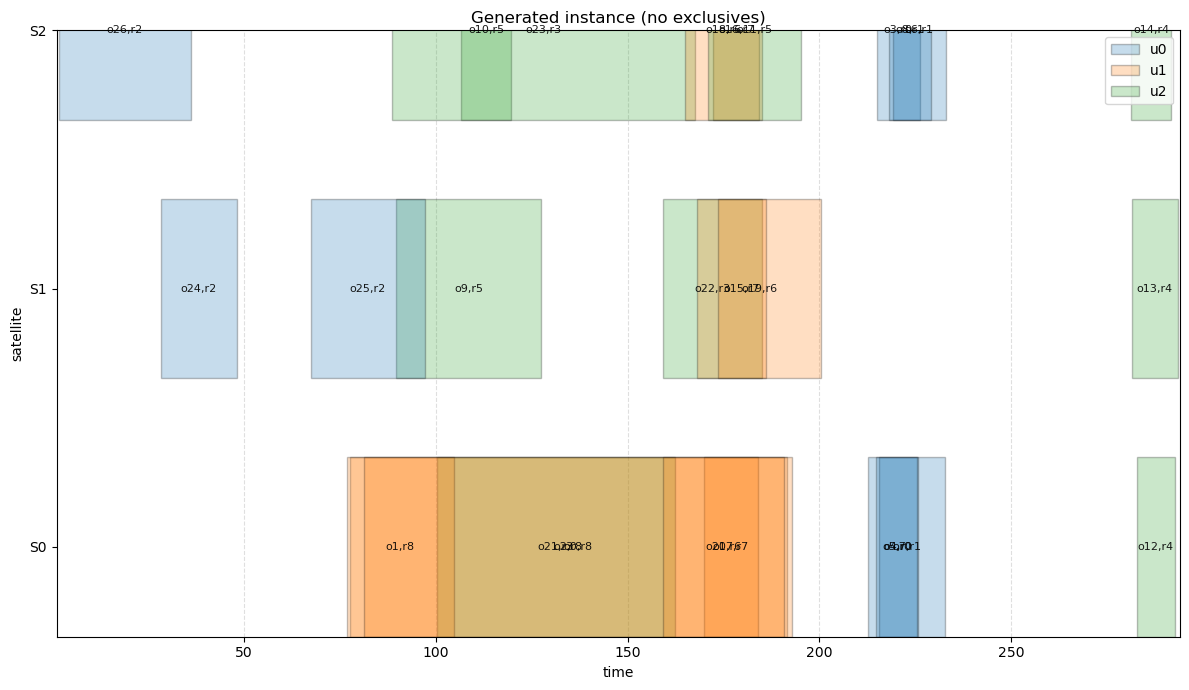

In [68]:
plot_eoscsp_windows(eoscsp_1, title="Generated instance (no exclusives)", show_labels=True,
    show_exclusives=True,
    show_plan_labels=True,)

#### 2.1.5 - Ajout de l'exclusivité

Rappel des modifications :
- User : e n'est plus à None, chaque fenêtre exclusive contient un satellite et un intervalle de temps
- Observation : si o est dans fenêtre exclusive alors o.u doit être propriétaire de cette exclusivité - si o appratient à u0 alors elle peut être dans une exclusivité ou hors de toutes les exclusivités 
- Contraintes globales : 1 - deux users différents ne peuvent pas utiliser la même exclusivité 2 - une observation non prioritaire ne peut pas intersecter une exclusivité
- Visualisation : zones hachurées du plot

In [69]:
horizon = 100.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 3.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

print(f"Generated: |S|={len(satellites)} |U|={len(users)} |R|={len(requests)} |O|={len(observations)}")

Generated: |S|=3 |U|=3 |R|=6 |O|=18


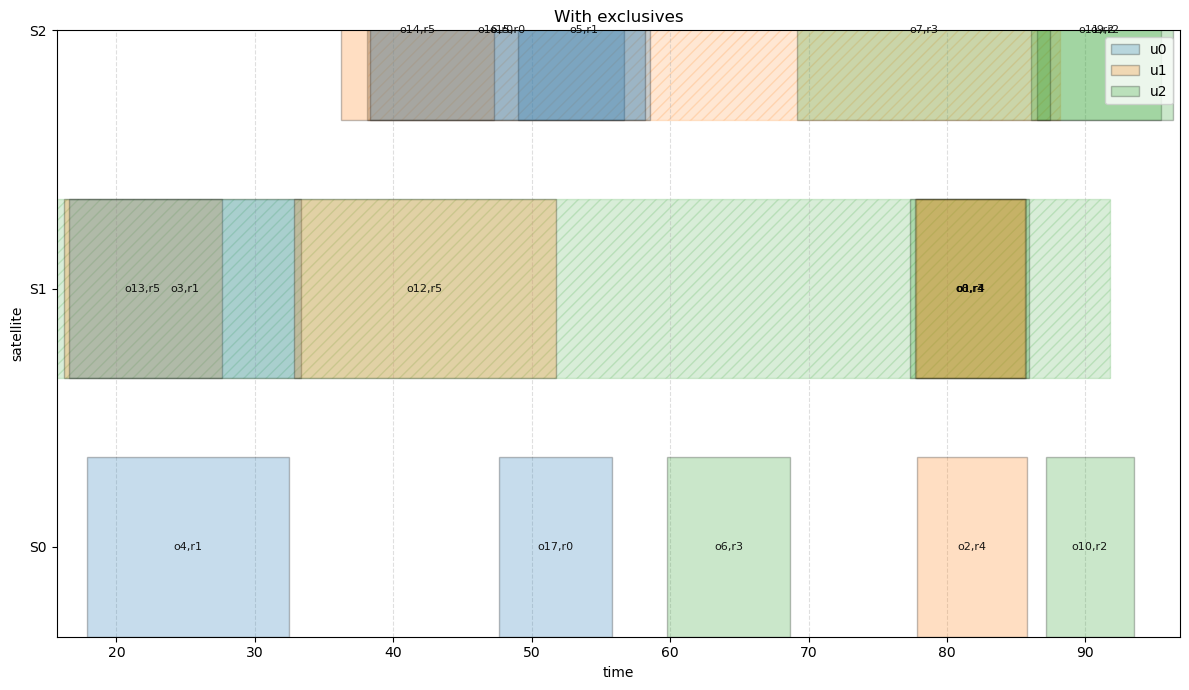

In [70]:
plot_eoscsp_windows(eoscsp_2, title="With exclusives", show_exclusives=True)

### 2.2 - Méthode de planification

Dans un second temps, nous allons concevoir une méthode de planification permettant à un utilisateur de planifier l’exécution d’un ensemble de tâches sur un satellite en tenant compte des contraintes temporelles sur ces tâches.

Dans le but de trouver une solution optimale du plan calculé, mais en limitant tout de même le temps de calcul nécessaire à cette génération, nous comptons implémenter une heuristique gloutonne.

DETAILLER PLUS TARD L'HEURISTIQUE SELON LE CHOIX D'IMPLEMENTATION


RAJOUTER NOTION DE PRIORITE OBSERVATION

#### Contraintes pour la solution

In [71]:
def feasible_window(o, start): # (10)
    return start + o.duration <= o.t_end

In [72]:
def feasible_transition(prev, prev_end, curr, start, tau, eps=1e-9):  # (5)(6)
    return start >= prev_end + tau(prev, curr) - eps

In [73]:
def feasible_no_overlap(start, end, plan): # non chevauchement réel
    for (_, s2, e2) in plan:
        if overlap(start, end, s2, e2):
            return False
    return True

In [74]:
def feasible_capacity(plan, sat): # (7)
    return len(plan) < sat.kappa

In [75]:
def feasible_one_obs_per_request(o, selected_requests): # (8)
    return o.r not in selected_requests

In [76]:
def feasible_exclusive(o, start, end, users): # exclusives (exécution réelle)
    for u in users:
        for (s,xs,xe) in u.e:
            if s == o.s and overlap(start, end, xs, xe):
                return o.u == u
    return True

#### Génération d'une solution

In [77]:
def gaps(plan, t_min, t_max):
    if not plan:
        return [(t_min, t_max, None, None)]

    plan = sorted(plan, key=lambda x: x[1])
    res = []

    # before first
    first = plan[0]
    if t_min < first[1]:
        res.append((t_min, first[1], None, first))

    # between
    for i in range(len(plan) - 1):
        prev_item = plan[i]
        next_item = plan[i + 1]
        if prev_item[2] < next_item[1]:
            res.append((prev_item[2], next_item[1], prev_item, next_item))

    # after last
    last = plan[-1]
    if last[2] < t_max:
        res.append((last[2], t_max, last, None))
    return res

In [78]:
# Vraiment utile ? hmmmmm
def check_plan_constraints(plan, users, sat, tau=lambda o, p: 0.0, eps=1e-9):
    errors = []

    # (7) Capacité satellite
    if len(plan) > sat.kappa:
        errors.append(
            f"(7) Capacity violated: |plan|={len(plan)} > kappa={sat.kappa}"
        )

    # (10) Fenêtres temporelles des observations
    for (o, s_exec, e_exec) in plan:
        if not (o.t_start - eps <= s_exec and e_exec <= o.t_end + eps):
            errors.append(
                f"(10) Window violated for obs o{getattr(o,'o_id','?')}: "
                f"planned [{s_exec:.2f},{e_exec:.2f}] "
                f"not in [{o.t_start:.2f},{o.t_end:.2f}]"
            )

    # Non-chevauchement + (5)(6) transitions
    plan_sorted = sorted(plan, key=lambda x: x[1])
    for (o1, s1, e1), (o2, s2, e2) in zip(plan_sorted, plan_sorted[1:]):

        # Non-chevauchement strict
        if overlap(s1, e1, s2, e2, eps=eps):
            errors.append(
                f"Overlap violated between obs o{getattr(o1,'o_id','?')} "
                f"and o{getattr(o2,'o_id','?')}"
            )

        # (5)(6) Transition tau
        if s2 < e1 + tau(o1, o2) - eps:
            errors.append(
                f"(5)(6) Transition violated between obs o{getattr(o1,'o_id','?')} "
                f"and o{getattr(o2,'o_id','?')}: "
                f"start2={s2:.2f} < end1+tau={e1+tau(o1,o2):.2f}"
            )

    # (8) Une observation au plus par requête
    seen_requests = set()
    for (o, _, _) in plan:
        r = getattr(o, "r", None)
        if r is None:
            continue
        if r in seen_requests:
            errors.append(
                f"(8) Request duplicated: r{getattr(r,'r_id','?')}"
            )
        seen_requests.add(r)

    # Exclusives : seul le propriétaire peut exécuter dans sa fenêtre exclusive
    for (o, s_exec, e_exec) in plan:
        for u in users:
            for (s_ex, xs, xe) in getattr(u, "e", []) or []:
                if getattr(s_ex, "s_id", None) != getattr(o.s, "s_id", None):
                    continue
                if overlap(s_exec, e_exec, xs, xe, eps=eps):
                    if o.u.u_id != u.u_id:
                        errors.append(
                            f"Exclusive violated on S{getattr(o.s,'s_id','?')}: "
                            f"obs o{getattr(o,'o_id','?')} (u{o.u.u_id}) "
                            f"overlaps exclusive of u{u.u_id} "
                            f"[{xs:.2f},{xe:.2f}]"
                        )

    return errors


In [79]:
def generate_solution(tasks, users=None, lam=0.1, eps=1e-6, tau=None, sol_id=0, debug=False):
    if not tasks:
        return Solution(sol_id, {}), 0.0, []

    if tau is None:
        tau = lambda a, b: 1.0

    # mono-satellite
    sids = {getattr(t.s, "s_id", id(t.s)) for t in tasks}
    if len(sids) != 1:
        raise ValueError("generate_solution() attend des tasks d'un seul satellite")

    sat = tasks[0].s
    t_min, t_max = sat.t_start, sat.t_end

    def score(o):
        slack = o.t_end - o.t_start
        return (o.reward / o.duration) + lam * (1.0 / max(slack, eps))

    tasks_sorted = sorted(tasks, key=lambda o: (-score(o), o.t_end))

    plan = []
    tot_reward = 0.0
    selected_requests = set()   # (8) one obs per request

    for o in tasks_sorted:
        # (7) capacity kappa
        if not feasible_capacity(plan, sat):
            break

        # (8) one obs per request
        if not feasible_one_obs_per_request(o, selected_requests):
            continue

        best_start = None
        candidate_gaps = gaps(plan, t_min=t_min, t_max=t_max)

        for (g_start, g_end, prev_item, next_item) in candidate_gaps:
            start = max(o.t_start, g_start)
            end = start + o.duration

            # (10) fenêtre de l'observation + doit tenir dans le gap
            if not feasible_window(o, start):
                continue
            if end > g_end + eps:
                continue

            # (5)(6) transition avec le précédent (si existe)
            if prev_item is not None:
                prev_obs, prev_start, prev_end = prev_item
                if not feasible_transition(prev_obs, prev_end, o, start, tau, eps=eps):
                    continue

            # (5)(6) transition avec le suivant (si existe)
            if next_item is not None:
                next_obs, next_start, next_end = next_item
                if end + tau(o, next_obs) > next_start + eps:
                    continue

            # Non-chevauchement (sécurité)
            if not feasible_no_overlap(start, end, plan):
                continue

            # Exclusives (exécution réelle)
            if users is not None and not feasible_exclusive(o, start, end, users):
                continue

            best_start = start
            break

        if best_start is not None:
            plan.append((o, best_start, best_start + o.duration))
            plan.sort(key=lambda x: x[1])
            tot_reward += o.reward
            selected_requests.add(o.r)

    # Optionnel: validation globale (debug)
    if debug and users is not None:
        errs = check_plan_constraints(plan, users, sat, tau=tau)
        if errs:
            raise RuntimeError("Plan violates constraints:\n- " + "\n- ".join(errs))

    M = {obs: start for (obs, start, end) in plan}
    return Solution(sol_id=sol_id, M=M), tot_reward, plan


In [80]:
def observations_one_user_one_satellite(observations, u_id, s_id):
    tasks = []
    for o in observations :
        if o.u.u_id == u_id and o.s.s_id == s_id:
            tasks.append(o)
    return tasks

#### Test sur une instance

In [81]:
horizon = 100.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 3.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

# user 0 et satellite 0
observations_u0 = observations_one_user_one_satellite(observations, 0, 0)

solution, reward, plan = generate_solution(observations_u0, tau=tau)

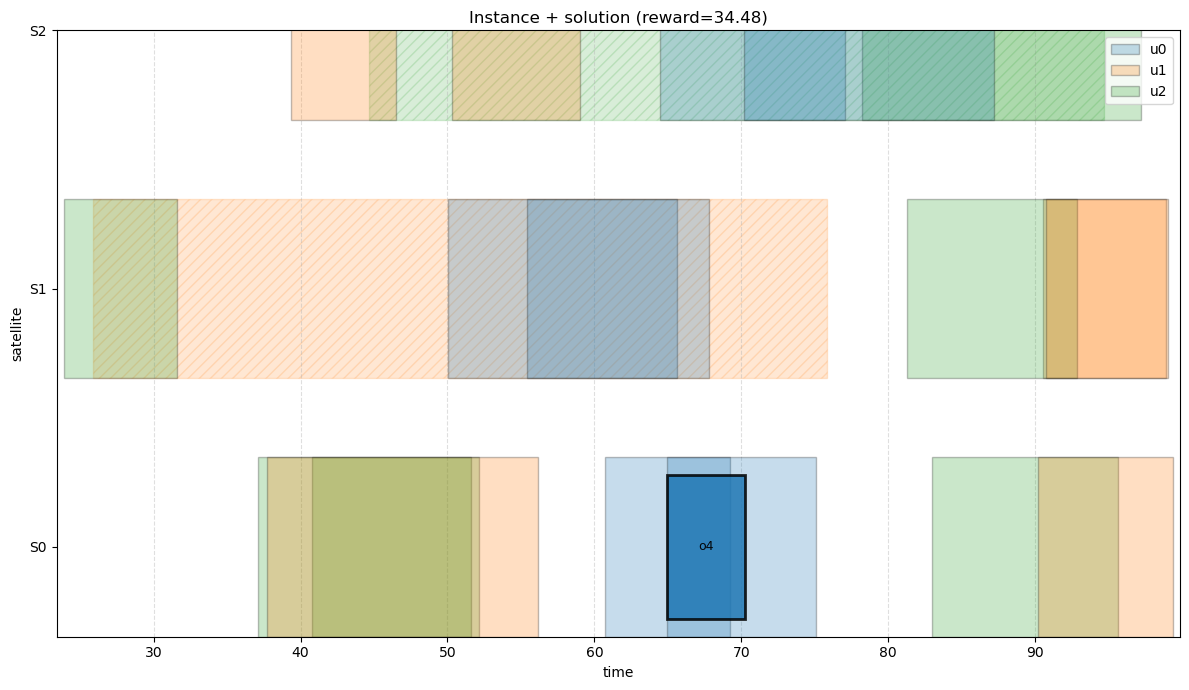

In [82]:
plot_eoscsp_windows(
    eoscsp_2,
    plan=plan,
    title=f"Instance + solution (reward={reward:.2f})",
    show_exclusives=True,
    show_labels=False,  
    show_plan_labels=True
)

In [83]:
# instance
P = generate_EOSCSP(2, satellites, users, requests, observations)
print(format_eoscsp(P, max_items=50))

EOSCSP instance #2
|S|=3 |U|=3 |R|=6 |O|=18

Satellites:
  S0: horizon=[0.00,100.00] kappa=166
  S1: horizon=[0.00,100.00] kappa=123
  S2: horizon=[0.00,100.00] kappa=185

Users:
  u0: priority=4 exclusives=0
  u1: priority=9 exclusives=1
    - (S1, [25.85,75.85])
  u2: priority=4 exclusives=1
    - (S2, [44.67,94.67])

Requests:
  r0: user=u0 duration=5.315135909815459 reward=34.47795637103107
  r1: user=u0 duration=6.327525092699197 reward=5.526254132403695
  r2: user=u1 duration=8.348135901205197 reward=13.61207527853988
  r3: user=u1 duration=3.3363152734243267 reward=30.563027821024395
  r4: user=u2 duration=7.363378417130073 reward=5.473996724855372
  r5: user=u2 duration=6.996188566746172 reward=31.685569075262922

Observations (windows):
  o16: u2 on S0 window=[37.11,52.17] dur=7.36 reward=5.47 (r4)
  o13: u1 on S0 window=[37.75,56.13] dur=3.34 reward=30.56 (r3)
  o15: u2 on S0 window=[40.80,51.59] dur=7.36 reward=5.47 (r4)
  o6: u0 on S0 window=[60.69,69.25] dur=6.33 reward=5.

In [84]:
print(format_solution(solution, title="Greedy planning solution"))

Greedy planning solution
Planned observations: 1

Total reward (sum of planned observations): 34.48

Satellite S0:
  o4 (r0 u0): start=64.96 end=70.28 dur=5.32 reward=34.48


## 3 - Partie 1 : Optimisation de contraintes distribuées

In [85]:
import pydcop
import yaml
import os

#### Exemple fichier yaml

In [86]:
# name: esop_instance_01
# objective: min

# domains:
#   time_t1:
#     values: ["NONE", 0, 10, 20, 30]
#   time_t2:
#     values: ["NONE", 0, 10, 20, 30]

# variables:
#   x_t1: {domain: time_t1}
#   x_t2: {domain: time_t2}

# constraints:
#   reward_t1:
#     type: intention
#     function: -12 if x_t1 != "NONE" else 0
#   reward_t2:
#     type: intention
#     function: -8 if x_t2 != "NONE" else 0

#   no_overlap_t1_t2:
#     type: intention
#     function: 1000000 if (x_t1 != "NONE" and x_t2 != "NONE" and not (x_t1+5 <= x_t2 or x_t2+7 <= x_t1)) else 0

# agents: [sat0, sat1]

#### Création fichier yaml

Le temps est discrétisé avec un pas Δ afin de limiter la taille des domaines et rendre le problème traitable par un solveur DCOP.

In [87]:
def instance_to_dcop(instance, delta=5):
    satellites = instance.S
    users = instance.U
    requests = instance.R
    observations = instance.O  
    
    dcop = {
        "name": f"EOSCSP_{instance.eoscsp_id}",
        "objective": "max",
        "domains": {},
        "variables": {},
        "constraints": {},
        "agents": []
    }

    # 1) agents
    dcop["agents"] = [f"sat{s.s_id}" for s in satellites]

    # 2) domains + variables (1 variable par tâche)
    for t in observations:
        values = ["NONE"]
        # discretize start times that fit window
        start = t.t_start
        while start + t.duration <= t.t_end:
            values.append(round(start, 2))
            start += delta

        dom_name = f"time_{t.o_id}"
        var_name = f"x_{t.o_id}"
        dcop["domains"][dom_name] = {"values": values}
        dcop["variables"][var_name] = {"domain": dom_name}

        # unary reward constraint
        dcop["constraints"][f"reward_{t.o_id}"] = {
            "type": "intention",
            "function": f"{t.reward} if {var_name} != 'NONE' else 0"
        }

    # 3) non-overlap constraints per satellite (pairwise)
    # group tasks by satellite
    tasks_by_sat = {}
    for t in observations:
        tasks_by_sat.setdefault(t.s.s_id, []).append(t)

    BIG = -1000000
    for sat_id, tasks in tasks_by_sat.items():
        for i in range(len(tasks)):
            for j in range(i+1, len(tasks)):
                t1, t2 = tasks[i], tasks[j]
                x1, x2 = f"x_{t1.o_id}", f"x_{t2.o_id}"
                d1, d2 = t1.duration, t2.duration
                cname = f"no_overlap_{t1.o_id}_{t2.o_id}"
                dcop["constraints"][cname] = {
                    "type": "intention",
                    "function": (
                        f"{BIG} if ({x1} != 'NONE' and {x2} != 'NONE' and "
                        f"not ({x1}+{d1} <= {x2} or {x2}+{d2} <= {x1})) else 0"
                    )
                }
    return dcop


def write_dcop_yaml(dcop, path):
    filename = dcop["name"] 
    filepath = os.path.join(path, filename)
    with open(filepath, "w", encoding="utf-8") as f:
        yaml.safe_dump(dcop, f, sort_keys=False, allow_unicode=True)

In [88]:
horizon = 100.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 3.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

dcop = instance_to_dcop(eoscsp_2, delta=5)

write_dcop_yaml(dcop, "yaml_files")

#### Algorithmes Pydcop

## 4 - Partie 2 : Approches par enchères

#### Exemple d'instance

In [89]:
horizon = 100.0

satellites = generate_satellites(3, horizon, 100, 200)
users_no_exclusifs = generate_users(1)
users_exclusifs = generate_users_exclusifs(len(users_no_exclusifs), satellites, 2)
users = users_no_exclusifs.union(users_exclusifs)
requests = generate_requests(users, 2, horizon, 3.0, 10.0, 5.0, 50.0)
observations = generate_observations(satellites, users, requests, 3, 6.0, 20.0)

eoscsp_2 = generate_EOSCSP(1, satellites, users, requests, observations)

In [90]:
P2 = generate_EOSCSP(3, satellites, users, requests, observations)
print(format_eoscsp(P2, max_items=50))

EOSCSP instance #3
|S|=3 |U|=3 |R|=6 |O|=15

Satellites:
  S0: horizon=[0.00,100.00] kappa=169
  S1: horizon=[0.00,100.00] kappa=112
  S2: horizon=[0.00,100.00] kappa=152

Users:
  u0: priority=1 exclusives=0
  u1: priority=10 exclusives=1
    - (S1, [0.15,78.30])
  u2: priority=1 exclusives=1
    - (S0, [43.07,93.07])

Requests:
  r0: user=u0 duration=4.040049895705641 reward=6.333292665678297
  r1: user=u0 duration=5.636157699775817 reward=39.29891502800846
  r2: user=u1 duration=9.85393465212715 reward=38.10161080690924
  r3: user=u1 duration=6.775109754028454 reward=6.055870015472272
  r4: user=u2 duration=9.275005493378272 reward=37.104032911586714
  r5: user=u2 duration=5.970721238011762 reward=12.265985802773006

Observations (windows):
  o1: u2 on S0 window=[5.83,25.31] dur=5.97 reward=12.27 (r5)
  o0: u2 on S0 window=[14.95,25.12] dur=5.97 reward=12.27 (r5)
  o12: u2 on S0 window=[28.66,44.95] dur=9.28 reward=37.10 (r4)
  o6: u1 on S0 window=[70.75,81.90] dur=6.78 reward=6.06 

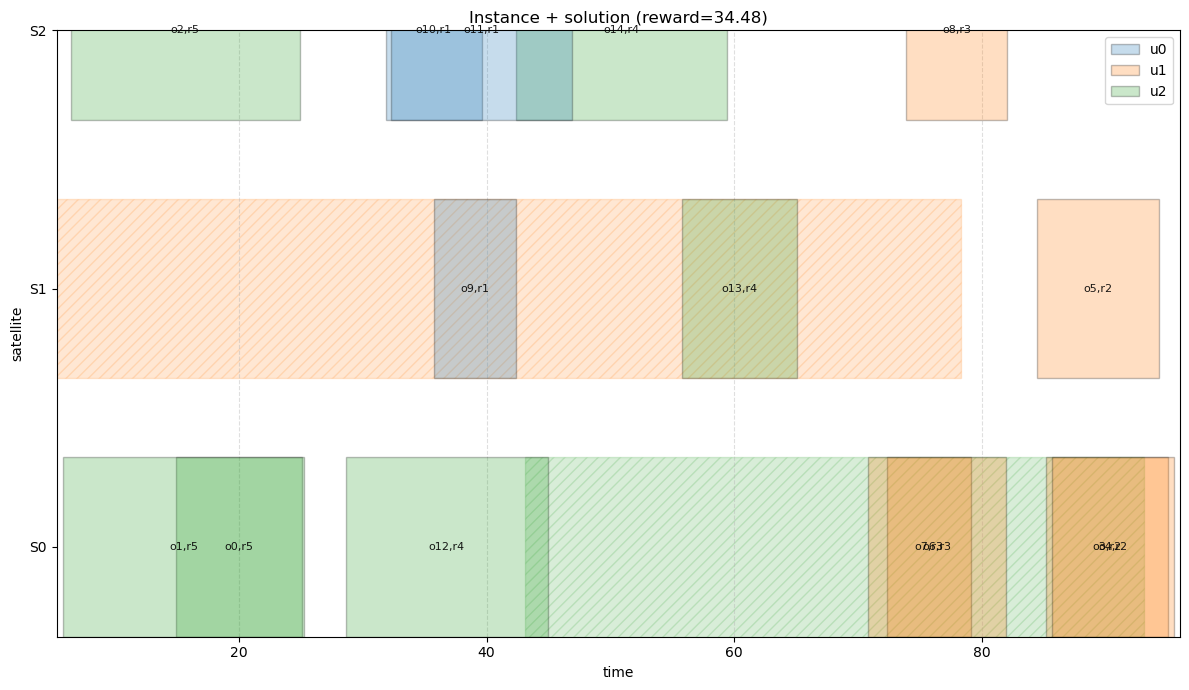

In [91]:
plot_eoscsp_windows(
    P2,
    plan=None,
    title=f"Instance + solution (reward={reward:.2f})",
    show_exclusives=True,
    show_labels=True,        # souvent mieux pour la lisibilité
    show_plan_labels=True
)

#### Suite

## 5 - Conclusion